# 04. RT-DETR-L (query-based)

Трансформерний детектор з того ж Ultralytics, щоб протокол був ідентичний YOLO з `02`: ті самі кадри train (кожен 5-й), той самий val, та сама оцінка, той самий бюджет 30 епох і `imgsz=640`.

Чим він принципово відрізняється від YOLO:
- модель має фіксований набір з 300 "запитів" (queries), кожен з яких або знаходить один об'єкт, або каже "нічого";
- під час тренування кожному справжньому об'єкту ставиться у відповідність рівно один query (угорський алгоритм, bipartite matching), тому дублікатів немає і NMS не потрібен;
- 300 queries покривають наш максимум на одному кадрі (180 об'єктів у train, розділ 5 EDA), але під час тренування mosaic може склеїти кілька кадрів в одну картинку, і тоді об'єктів буває більше, ніж queries.

Ще одна відмінність від YOLO: RT-DETR розтягує кадр до квадрата 640×640, а YOLO зберігає пропорції (кадр 16:9 стає приблизно 640×360). Тобто при тому самому `imgsz` RT-DETR бачить більше пікселів по вертикалі, і це треба враховувати при порівнянні.

Batch 8 замість 16, бо RT-DETR-L важчий за YOLO11s. Ultralytics накопичує градієнти до номінального batch 64, тож ефективний крок оптимізатора той самий. Версія `ultralytics` та сама, що в `02` (8.4.193).

Потрібно: GPU T4 і увімкнений Internet.

## 0. Налаштування

In [1]:
%pip install -q ultralytics==8.4.193 pycocotools

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import os
import time
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import torch

os.environ["WANDB_MODE"] = "disabled"
os.environ["YOLO_VERBOSE"] = "False"

import ultralytics
from ultralytics import RTDETR
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

ultralytics.settings.update({"wandb": False, "raytune": False})

SEED = 42
CLASSES = ["person", "bicycle", "car", "van", "truck", "tricycle", "bus", "motor"]

MODEL = "rtdetr-l.pt"
RUN_NAME = "rtdetr_l_640"
IMGSZ = 640
BATCH = 8
EPOCHS = 30
STEP = 5

print("ultralytics", ultralytics.__version__, "| torch", torch.__version__, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "немає")

ultralytics 8.4.193 | torch 2.11.0+cu128 | GPU: Tesla T4


Шукаємо дані так само, як в `01_eda`. Усі результати пишемо в `/kaggle/working`, звідти Kaggle зберігає їх після запуску.

In [3]:
ROOT = next(
    path.parent
    for pattern in ["*/test_images.csv", "*/*/test_images.csv", "*/*/*/test_images.csv"]
    for path in Path("/kaggle/input").glob(pattern)
)
OUT = Path("/kaggle/working")
print(ROOT)

/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026


## 1. Дані для тренування

Ultralytics вміє брати список картинок з текстового файлу, а мітки сам шукає в сусідній папці `labels`. Тому нічого не копіюємо: робимо список кожного 5-го кадру train і список усіх кадрів val.

In [4]:
def frame_list(split):
    return pl.DataFrame({"path": sorted(str(path) for path in (ROOT / split / "images").rglob("*.jpg"))}).with_columns(
        video=pl.col("path").str.split("/").list.get(-2)
    )


train_frames = frame_list("train").filter((pl.int_range(pl.len()).over("video") % STEP) == 0)
val_frames = frame_list("val")

(OUT / "train_list.txt").write_text("\n".join(train_frames["path"]))
(OUT / "val_list.txt").write_text("\n".join(val_frames["path"]))

(OUT / "data.yaml").write_text(
    f"train: {OUT / 'train_list.txt'}\n"
    f"val: {OUT / 'val_list.txt'}\n"
    f"nc: {len(CLASSES)}\n"
    f"names: {json.dumps(CLASSES)}\n"
)

print("train:", train_frames.height, "кадрів з", train_frames["video"].n_unique(), "відео")
print("val:", val_frames.height, "кадрів з", val_frames["video"].n_unique(), "відео")

train: 4868 кадрів з 56 відео
val: 2846 кадрів з 7 відео


## 2. Тренування

Стартуємо з ваг RT-DETR-L, натренованих на COCO. Налаштування за замовчуванням, крім batch (див. вище), кількості епох і seed. Відомо, що DETR-моделі сходяться повільніше за CNN, тому за ті самі 30 епох модель може не встигнути навчитися до кінця. Це якраз те, що треба показати на графіку нижче. Після кожної епохи друкуємо один рядок з mAP, щоб у логах було видно, як іде тренування.

In [5]:
model = RTDETR(MODEL)
start = time.time()


def log_epoch(trainer):
    if trainer.epoch < trainer.epochs:
        print(f"епоха {trainer.epoch + 1}/{trainer.epochs} | {(time.time() - start) / 60:.0f} хв | mAP50-95 {trainer.metrics.get('metrics/mAP50-95(B)', float('nan')):.4f}", flush=True)


model.add_callback("on_fit_epoch_end", log_epoch)
model.train(
    data=str(OUT / "data.yaml"),
    imgsz=IMGSZ,
    batch=BATCH,
    epochs=EPOCHS,
    seed=SEED,
    deterministic=True,
    workers=4,
    device=0,
    project=str(OUT / "runs"),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
)
train_hours = (time.time() - start) / 3600
actual_batch, accumulate = model.trainer.batch_size, model.trainer.accumulate
print(f"тренування: {train_hours:.2f} год | batch {actual_batch}, accumulate {accumulate}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


епоха 1/30 | 9 хв | mAP50-95 0.1703


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


епоха 2/30 | 15 хв | mAP50-95 0.2123


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


епоха 3/30 | 22 хв | mAP50-95 0.2208


... (50 outputs left out)

/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


епоха 29/30 | 187 хв | mAP50-95 0.1962


/usr/local/lib/python3.13/dist-packages/torch/autograd/graph.py:869: UserWarning: grid_sampler_2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:160.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


епоха 30/30 | 193 хв | mAP50-95 0.1925
тренування: 3.24 год | batch 8, accumulate 8


Криві тренування. У RT-DETR інші лоси, ніж у YOLO: `giou_loss` і `l1_loss` для рамок, `cls_loss` для класу. Криву mAP потім покладемо поруч з кривою YOLO з `02`, як просить завдання.

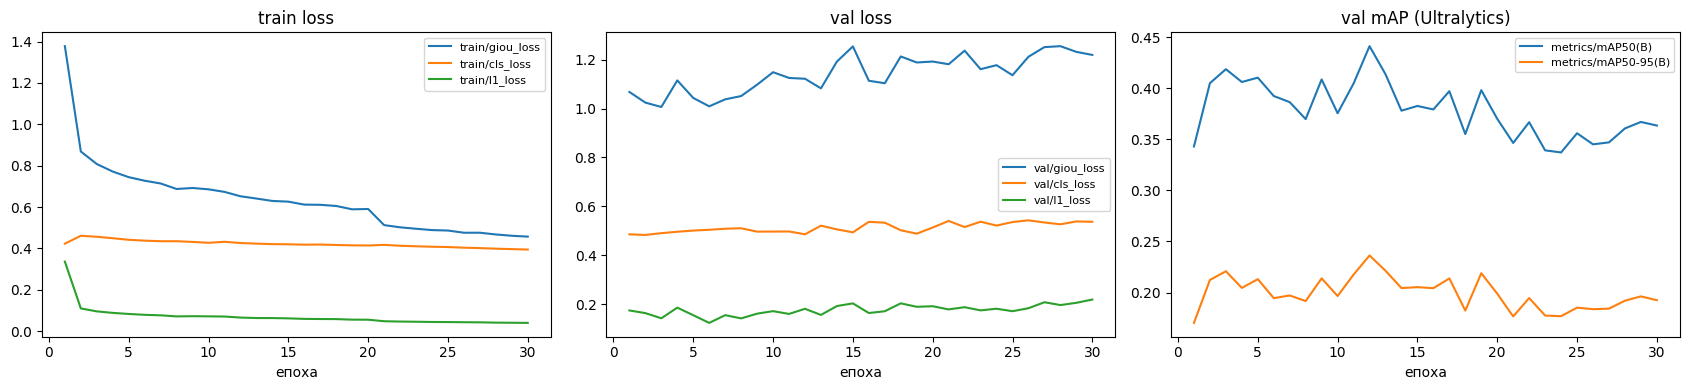

In [6]:
run_dir = OUT / "runs" / RUN_NAME
history = pl.read_csv(run_dir / "results.csv")
history = history.rename({name: name.strip() for name in history.columns})
train_losses = [name for name in history.columns if name.startswith("train/")]
val_losses = [name for name in history.columns if name.startswith("val/")]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for name in train_losses:
    axes[0].plot(history["epoch"], history[name], label=name)
for name in val_losses:
    axes[1].plot(history["epoch"], history[name], label=name)
for name in ["metrics/mAP50(B)", "metrics/mAP50-95(B)"]:
    axes[2].plot(history["epoch"], history[name], label=name)
axes[0].set_title("train loss")
axes[1].set_title("val loss")
axes[2].set_title("val mAP (Ultralytics)")
for ax in axes:
    ax.set_xlabel("епоха")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

## 3. Оцінка на val за нашим протоколом

Метрики Ultralytics не враховують ignored regions і не рахують AP_small, тому робимо свою оцінку:
- передбачаємо всі кадри val з низьким порогом впевненості (0.001), бо mAP сам перебирає пороги;
- кадри подаємо порціями по 16: якщо передати весь список одразу, Ultralytics завантажує всі картинки в пам'ять, і на кадрах 4K закінчується RAM;
- `max_det=500`, як на Kaggle;
- переводимо рамки в COCO-формат і рахуємо `COCOeval` з оригінальним `annotations_coco.json` (там ignored regions уже позначені `iscrowd = 1`);
- у `COCOeval` ставимо ліміт 500 детекцій на кадр замість стандартних 100, бо в нас буває до 180 об'єктів на кадрі.

In [7]:
best = RTDETR(run_dir / "weights" / "best.pt")

val_coco = json.loads((ROOT / "val" / "annotations_coco.json").read_text())
image_ids = {"/".join(Path(image["file_name"]).parts[-2:]): image["id"] for image in val_coco["images"]}

val_paths = val_frames["path"].to_list()
detections = []
speeds = []
for chunk_start in range(0, len(val_paths), 16):
    for result in best.predict(source=val_paths[chunk_start:chunk_start + 16], batch=16, imgsz=IMGSZ, conf=0.001, max_det=500, verbose=False, device=0):
        speeds.append(sum(result.speed.values()))
        height, width = result.orig_shape
        boxes = result.boxes.xyxy.cpu().numpy().clip(0, [width, height, width, height])
        detections += [
            {"image_id": image_ids["/".join(Path(result.path).parts[-2:])], "category_id": int(cls) + 1, "bbox": [round(float(x1), 2), round(float(y1), 2), round(float(x2 - x1), 2), round(float(y2 - y1), 2)], "score": round(float(score), 4)}
            for (x1, y1, x2, y2), cls, score in zip(boxes, result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy())
        ]

(OUT / f"val_predictions_{RUN_NAME}.json").write_text(json.dumps(detections))
ms_per_image = float(np.mean(speeds))
print(len(detections), "детекцій на", len(image_ids), "кадрах;", f"{ms_per_image:.1f} ms/кадр")

853800 детекцій на 2846 кадрах; 41.6 ms/кадр


In [8]:
ground_truth = COCO(str(ROOT / "val" / "annotations_coco.json"))
evaluator = COCOeval(ground_truth, ground_truth.loadRes(str(OUT / f"val_predictions_{RUN_NAME}.json")), "bbox")
evaluator.params.maxDets = [1, 100, 500]
evaluator.evaluate()
evaluator.accumulate()
evaluator.summarize()

loading annotations into memory...
Done (t=0.42s)
creating index...
index created!
Loading and preparing results...
DONE (t=5.17s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=193.61s).
Accumulating evaluation results...
DONE (t=12.02s).
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.240
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=500 ] = 0.448
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=500 ] = 0.228
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=500 ] = 0.097
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=500 ] = 0.217
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=500 ] = 0.389
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.127
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.409
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxD

Зводимо головні цифри в один рядок і зберігаємо в файл. Головний mAP рахуємо сам з таблиці precision при ліміті 500 детекцій: `summarize()` у `pycocotools` перший рядок завжди рахує з лімітом 100, навіть якщо змінити `maxDets`.

In [9]:
stats = evaluator.stats
precision_500 = evaluator.eval["precision"][:, :, :, 0, -1]
result_row = {
    "run": RUN_NAME,
    "model": MODEL,
    "imgsz": IMGSZ,
    "batch": actual_batch,
    "accumulate": accumulate,
    "epochs": EPOCHS,
    "train_frames": train_frames.height,
    "mAP": round(float(np.mean(precision_500[precision_500 > -1])), 4),
    "mAP_maxdet100": round(stats[0], 4),
    "AP50": round(stats[1], 4),
    "AP75": round(stats[2], 4),
    "AP_small": round(stats[3], 4),
    "AP_medium": round(stats[4], 4),
    "AP_large": round(stats[5], 4),
    "AR500": round(stats[8], 4),
    "ms_per_image": round(ms_per_image, 1),
    "train_hours": round(train_hours, 2),
}
(OUT / f"result_{RUN_NAME}.json").write_text(json.dumps(result_row, indent=2))
pl.DataFrame([result_row])

run,model,imgsz,batch,accumulate,epochs,train_frames,mAP,mAP_maxdet100,AP50,AP75,AP_small,AP_medium,AP_large,AR500,ms_per_image,train_hours
str,str,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""rtdetr_l_640""","""rtdetr-l.pt""",640,8,8,30,4868,0.2403,0.2399,0.448,0.2285,0.0972,0.2169,0.389,0.4121,41.6,3.24


AP по кожному класу окремо: середній mAP може ховати класи, які модель майже не знаходить.

In [10]:
precision = evaluator.eval["precision"][:, :, :, 0, -1]
pl.DataFrame(
    [
        {
            "class": name,
            "AP": round(float(np.mean(precision[:, :, i][precision[:, :, i] > -1])), 4) if (precision[:, :, i] > -1).any() else None,
            "AP50": round(float(np.mean(precision[0, :, i][precision[0, :, i] > -1])), 4) if (precision[0, :, i] > -1).any() else None,
        }
        for i, name in enumerate(CLASSES)
    ]
)

class,AP,AP50
str,f64,f64
"""person""",0.261,0.6256
"""bicycle""",0.1364,0.3299
"""car""",0.3937,0.6115
"""van""",0.2462,0.3976
"""truck""",0.1694,0.3314
"""tricycle""",0.2049,0.439
"""bus""",0.3982,0.515
"""motor""",0.1127,0.3339


## 4. Сабміт на Kaggle

Передбачаємо всі кадри test з тими самими налаштуваннями. На відміну від YOLO, RT-DETR не обрізає рамки по краях кадру, тому обрізаємо їх самі (так само і для val вище). Формат рядка: `class score x y width height`, де (x, y) — лівий верхній кут у пікселях оригінального кадру. Ultralytics повертає рамки вже в пікселях оригіналу, тож лишається перевести кути в ширину і висоту. Кадри без детекцій лишаються з порожнім рядком.

In [11]:
test_images = pl.read_csv(ROOT / "test_images.csv")
test_ids = {"/".join(Path(file_name).parts[-2:]): image_id for image_id, file_name in test_images.select("image_id", "file_name").iter_rows()}

test_paths = [str(ROOT / file_name) for file_name in test_images["file_name"]]
predictions = {}
for chunk_start in range(0, len(test_paths), 16):
    for result in best.predict(source=test_paths[chunk_start:chunk_start + 16], batch=16, imgsz=IMGSZ, conf=0.001, max_det=500, verbose=False, device=0):
        height, width = result.orig_shape
        boxes = result.boxes.xyxy.cpu().numpy().clip(0, [width, height, width, height])
        predictions[test_ids["/".join(Path(result.path).parts[-2:])]] = " ".join(
            f"{int(cls)} {score:.4f} {x1:.1f} {y1:.1f} {x2 - x1:.1f} {y2 - y1:.1f}"
            for (x1, y1, x2, y2), cls, score in zip(boxes, result.boxes.cls.cpu().numpy(), result.boxes.conf.cpu().numpy())
        )

submission = test_images.select("image_id").with_columns(
    PredictionString=pl.col("image_id").replace_strict(predictions, default="")
)
submission.write_csv(OUT / "submission.csv")
submission.write_csv(OUT / f"submission_{RUN_NAME}.csv")
print(submission.height, "рядків,", (submission["PredictionString"] == "").sum(), "порожніх")
submission.head()

3811 рядків, 0 порожніх


image_id,PredictionString
str,str
"""clip_001_0000001""","""0 0.8318 628.6 916.4 63.9 163.…"
"""clip_001_0000002""","""0 0.8314 622.0 924.9 66.7 155.…"
"""clip_001_0000003""","""0 0.8297 613.8 933.3 69.0 146.…"
"""clip_001_0000004""","""0 0.8255 756.5 900.9 71.7 176.…"
"""clip_001_0000005""","""0 0.8359 724.2 914.3 74.8 165.…"


Перевірка формату перед відправкою: кількість рядків як у `test_images.csv`, у кожній групі 6 чисел, класи від 0 до 7, рамки не виходять за межі кадру.

In [12]:
rows = (
    submission.join(test_images.select("image_id", "width", "height"), on="image_id")
    .filter(pl.col("PredictionString") != "")
    .with_columns(values=pl.col("PredictionString").str.split(" ").cast(pl.List(pl.Float64)))
)
boxes = rows.select(
    "width",
    "height",
    *[pl.col("values").list.gather_every(6, offset).alias(name) for offset, name in enumerate(["cls", "score", "x", "y", "w", "h"])],
).explode("cls", "score", "x", "y", "w", "h")

{
    "рядків як у test_images.csv": submission.height == test_images.height,
    "кількість чисел кратна 6": rows.select((pl.col("values").list.len() % 6 == 0).all()).item(),
    "не більше 500 рамок на кадр": rows.select((pl.col("values").list.len() <= 6 * 500).all()).item(),
    "класи від 0 до 7": boxes["cls"].is_between(0, 7).all(),
    "score від 0 до 1": boxes["score"].is_between(0, 1).all(),
    "рамки в межах кадру": boxes.select(
        ((pl.col("x") >= -1) & (pl.col("y") >= -1) & (pl.col("x") + pl.col("w") <= pl.col("width") + 1) & (pl.col("y") + pl.col("h") <= pl.col("height") + 1)).all()
    ).item(),
}

{'рядків як у test_images.csv': True,
 'кількість чисел кратна 6': True,
 'не більше 500 рамок на кадр': True,
 'класи від 0 до 7': True,
 'score від 0 до 1': True,
 'рамки в межах кадру': True}